# 06. MobileNetV3 + SIFT/RANSAC: проверка конкретного экземпляра POI

Предыдущие варианты путали похожие здания. Здесь проверяется согласованное расположение локальных деталей.
MobileNetV3/Ridge предлагает 5 POI; для каждого проверяются 3 ближайших train-эталона.
SIFT извлекается без обучения и скачивания весов. FLANN/ratio test и RANSAC дают геометрическую поддержку.
Исходники, прежние модели и разбиения сохраняются.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image as DisplayImage
ROOT=Path.cwd().resolve()
if not (ROOT/'config/mobilenetv3_geometric.json').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.poi_baseline import sha256_file
from src.poi_geometry import GeometricPOIVerifier
OUTPUT=ROOT/'models/mobilenetv3_geometric'
assert (OUTPUT/'metadata.json').exists(), 'Сначала завершите scripts/geometric_poi.py'
metadata=json.loads((OUTPUT/'metadata.json').read_text())
for name,digest in metadata['artifact_sha256'].items():assert sha256_file(OUTPUT/name)==digest,name
for name,digest in metadata['input_split_sha256'].items():assert sha256_file(ROOT/f'data/annotations/{name}.csv')==digest,name
display(pd.Series(json.loads((OUTPUT/'config.json').read_text())))


I:\Невидаль\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed                                                        42
candidate_pois                                               5
references_per_poi                                           3
image_long_side                                            960
sift_features                                             1200
sift_contrast_threshold                                   0.02
ratio_test                                                0.72
minimum_matches                                              8
minimum_inliers                                              8
minimum_coverage                                          0.02
ransac_reprojection_threshold                              4.0
ransac_max_iterations                                     1500
score_aggregations                            [best, mean_two]
score_fusions                    [geometry_only, hybrid_ridge]
minimum_score_threshold                                   0.01
target_known_wrong_far                                 

## 1. Протокол

Train-галерея состоит из прежних 404 эталонов, с source/author/licence. Новые POI и negatives в неё не добавляются.
Локальные признаки вычисляются на EXIF-corrected grayscale копиях с длинной стороной ≤960.
Ratio test=0.72. Разные query keypoints не голосуют за один ref keypoint.
Геометрическая поддержка требует ≥8 RANSAC inliers и покрытия ≥2% каждого кадра.
Это критерий решения модели, а не автоматическое исключение изображений из датасета.

Сравниваются два способа агрегации и две fusion-стратегии:
`geometry_only` требует геометрии; `hybrid_ridge` добавляет Ridge-отклик и допускает строгий fallback.
Глобальные score/margin пороги и вариант выбираются только на positive-val/negative-val,
с ограничениями external any-POI FAR ≤1%, known hard-wrong FAR ≤5% на validation.
Test вычисляется после фиксации selection.json. Пороги по test не подстраиваются.


In [2]:
display(pd.read_csv(OUTPUT/'validation_candidates.csv'))
display(pd.Series(json.loads((OUTPUT/'selection.json').read_text())))
display(pd.Series(json.loads((OUTPUT/'rejection_policy.json').read_text())))
display(pd.read_csv(OUTPUT/'gallery.csv',keep_default_na=False)[['image_id','poi_id','source','author','licence']].head())


,accuracy,macro_f1,aggregation,score_fusion,true_accept_rate,external_any_poi_far
0,0.867550,0.855891,best,geometry_only,0.291391,0.008726
1,0.867550,0.855891,best,hybrid_ridge,0.370861,0.008726
2,0.860927,0.847834,mean_two,geometry_only,0.291391,0.008726
3,0.867550,0.855891,mean_two,hybrid_ridge,0.304636,0.005236


aggregation                                best
score_fusion                       hybrid_ridge
selection_split            val_and_negative_val
test_used_for_selection                   False
dtype: object

score_threshold                                                             0.01
margin_threshold                                                         0.68061
true_accept_rate                                                        0.370861
known_wrong_far                                                              0.0
hard_wrong_far                                                               0.0
tp                                                                            56
fp                                                                             0
external_any_poi_far                                                    0.008726
external_false_accepts                                                         5
calibration_split                                                            val
target_known_wrong_far                                                      0.01
target_hard_wrong_far                                                       0.05
negative_scope              

,image_id,poi_id,source,author,licence
0,wm_d278caa4f75eb01d,moscow/arbat/arseny_morozov_house,wikimedia_commons,Tatiana El-Bakri,CC BY-SA 2.0
1,wm_59c8de5bc1409546,moscow/arbat/arseny_morozov_house,wikimedia_commons,Mike1979 Russia,CC BY-SA 4.0
2,wm_5d6536ae4516d652,moscow/arbat/arseny_morozov_house,wikimedia_commons,sailko,CC BY-SA 3.0
3,wm_d55c42b1e80697eb,moscow/arbat/arseny_morozov_house,wikimedia_commons,This file comes from the official website of t...,CC BY 4.0
4,wm_d1f1f53d24c87570,moscow/arbat/arseny_morozov_house,wikimedia_commons,"Andrey Filippov 安德烈 from Moscow, Russia",CC BY 2.0


## 2. Test: классификация, true accept и external FAR

Без геометрии ranking может опираться на coarse Ridge; это не равнозначно подтверждению цели.
Score — непробабилистическая комбинация геометрической согласованности и, в hybrid, Ridge-отклика.
Глобальный FAR не гарантирует одинаковое качество для каждого POI или невиданных типов negatives.


,split,accuracy,macro_f1,true_accept,external_any_poi_far
0,val,0.867550,0.855891,0.370861,0.008726
1,test,0.849315,0.847035,0.308219,0.010471


,poi_id,query_count,top1_accuracy,true_accept_rate,known_wrong_far,true_accepts,wrong_accepts
0,moscow/arbat/arseny_morozov_house,7,1.000000,0.285714,0.0,2,0
1,moscow/arbat/pashkov_house,7,1.000000,0.285714,0.0,2,0
2,moscow/khamovniki/khrushchev_seleznev_house,5,0.600000,0.000000,0.0,0,0
3,moscow/khamovniki/pushkin_museum,6,0.666667,0.166667,0.0,1,0
4,moscow/ostankinskiy/armenia,6,0.833333,0.333333,0.0,2,0
5,moscow/ostankinskiy/central_pavilion,6,0.666667,0.166667,0.0,1,0
6,moscow/ostankinskiy/cosmos,7,1.000000,0.285714,0.0,2,0
7,moscow/ostankinskiy/main_entrance,7,1.000000,0.285714,0.0,2,0
8,moscow/ostankinskiy/moscow_sun,8,0.875000,0.375000,0.0,3,0
9,moscow/ostankinskiy/ostankino_tower,10,0.900000,0.300000,0.0,3,0


,group_by,group,images,false_accepts,any_poi_far
0,negative_type,similar_arch,48,0,0.00
1,negative_type,similar_classical_building,100,6,0.06
2,negative_type,similar_decorated_building,50,0,0.00
3,negative_type,similar_hotel,98,0,0.00
4,negative_type,similar_mansion,50,0,0.00
5,negative_type,similar_pavilion,177,0,0.00
6,negative_type,similar_tower,50,0,0.00
7,source_poi_id,moscow/aeroport/petrovsky_palace,50,0,0.00
8,source_poi_id,moscow/donskoy/shukhov_tower,50,0,0.00
9,source_poi_id,moscow/dorogomilovo/hotel_ukraina,50,0,0.00


Статус: not_promoted_far_exceeded
Время только matching, без SIFT/decode/encoder: {'test': {'mean': 0.32577397260290236, 'p95': 0.43324999998731073}, 'negative_test': {'mean': 0.32329668411869233, 'p95': 0.4529999999795109}}


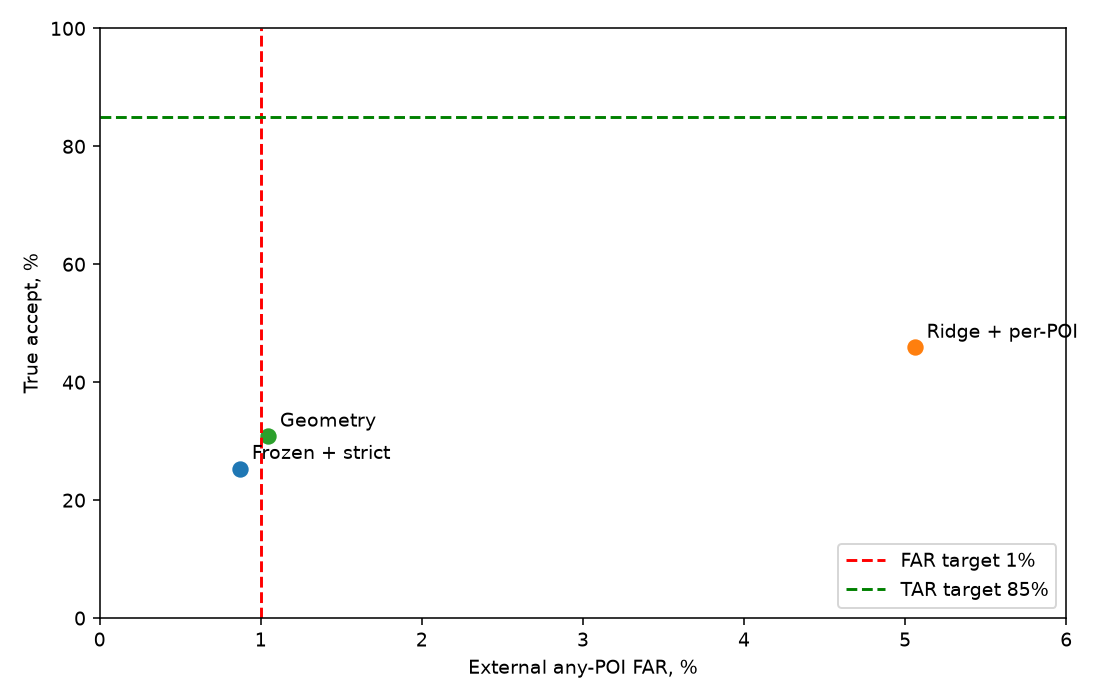

In [3]:
metrics=json.loads((OUTPUT/'metrics.json').read_text())
display(pd.DataFrame([{'split':s,'accuracy':metrics[s]['accuracy'],'macro_f1':metrics[s]['macro_f1'],
 'true_accept':metrics[s]['true_accept_rate'],'external_any_poi_far':metrics[f'negative_{s}']['any_poi_far']}
 for s in ['val','test']]))
display(pd.read_csv(OUTPUT/'test_per_poi.csv'))
display(pd.read_csv(OUTPUT/'negative_test_groups.csv'))
print('Статус:',metadata['deployment_status'])
print('Время только matching, без SIFT/decode/encoder:',metadata['matching_only_latency_seconds'])
display(DisplayImage(filename=str(ROOT/'reports/mobilenetv3_geometric/test_tradeoff.png')))


## 3. Разбор решений

Файлы `*_evidence.csv` содержат query ID, цель, ref ID, число совпадений и inliers,
доли покрытия и geometric_score. Таблицы `*_predictions.csv` сохраняют разметку и атрибуцию.
Смотреть ошибки test можно для диагностики; текущий выпуск после этого не перенастраивается.


In [4]:
evidence=pd.read_csv(OUTPUT/'test_evidence.csv',keep_default_na=False)
display(evidence.sort_values('geometric_score',ascending=False).head(20))
negative=pd.read_csv(OUTPUT/'negative_test_predictions.csv',keep_default_na=False)
display(negative[negative.accepted_any_poi][['image_id','source_poi_id','predicted_poi_id','score','margin']])


,image_id,target_poi_id,reference_image_id,matches,inliers,inlier_ratio,query_coverage,reference_coverage,geometric_score
810,manual_c1546dbb2e14fabe,moscow/ostankinskiy/pavilion_71,manual_621f93b8433993d3,252,225,0.892857,0.406309,0.407588,3.084979
555,manual_823bedc812ffbf22,moscow/ostankinskiy/moldova_pavilion,manual_f93448de0974cf05,126,109,0.865079,0.797126,0.194001,1.791021
180,manual_25f9ffec0f2c73e2,moscow/ostankinskiy/pavilion_71,manual_d663a5576e63a45a,181,115,0.635359,0.450950,0.343442,1.769978
557,manual_823bedc812ffbf22,moscow/ostankinskiy/moldova_pavilion,manual_d657b058279c2f7f,117,89,0.760684,0.761144,0.221323,1.610318
1322,wm_34e7bcb99fa0b1b7,moscow/tverskoy/bolshoi_theatre,wm_897ba79b8e76d2a4,110,86,0.781818,0.375668,0.203876,1.576515
556,manual_823bedc812ffbf22,moscow/ostankinskiy/moldova_pavilion,manual_108dc026877e6ab9,135,90,0.666667,0.599215,0.266206,1.551590
947,manual_d6b9a29eaba63e81,moscow/ostankinskiy/pavilion_71,manual_7725206c51ba440f,156,130,0.833333,0.128296,0.549653,1.455180
450,manual_669f4b9ef53657fd,moscow/ostankinskiy/pavilion_71,manual_1b56873376a593a5,59,40,0.677966,0.360596,0.332104,1.450898
1815,wm_b844f41d946f3d0f,moscow/ostankinskiy/armenia,wm_d48d84bb562adab8,111,85,0.765766,0.522745,0.173987,1.422780
1426,wm_521bdfeb23d68241,moscow/ostankinskiy/main_entrance,wm_833c347171fae2c9,98,54,0.551020,0.363469,0.291473,1.192127


,image_id,source_poi_id,predicted_poi_id,score,margin
88,neg_2f7ab1f557d944df,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,0.918498,0.721799
225,neg_635708ac0f0efda6,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,0.967572,0.692862
257,neg_75236cd0bd499b16,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,1.257510,0.970642
379,neg_a8bcc62268164a33,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,1.161711,0.831873
495,neg_dd52c86fa5ce4e0d,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,0.950868,0.704144
548,neg_f48ebb9f86dd40fc,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,0.937354,0.718651


## 4. Одиночная проверка

Seed зависит только от train-эталона, поэтому одинаковые пиксели дают одинаковую геометрию
в пакетном и одиночном выводе независимо от ID или имени загружаемого файла.


In [5]:
verifier=GeometricPOIVerifier(OUTPUT)
test=pd.read_csv(OUTPUT/'splits/test.csv',keep_default_na=False)
example=test.iloc[0]
display(pd.Series(verifier.verify(ROOT/example.file_path,example.poi_id)))
# verifier.verify(Path('path/to/photo.jpg'),'moscow/ostankinskiy/ostankino_tower')


Geometric reranking:   0%|          | 0/1 [00:00<?, ?it/s]

Geometric reranking: 100%|██████████| 1/1 [00:00<00:00,  2.66it/s]

Geometric reranking: 100%|██████████| 1/1 [00:00<00:00,  2.65it/s]

accepted                                                             False
reason                                                       poi_ambiguous
target_poi_id                moscow/ostankinskiy/friendship_of_the_peoples
predicted_poi_id             moscow/ostankinskiy/friendship_of_the_peoples
score                                                             0.816608
margin                                                             0.64348
score_type                 sift_ransac_plus_ridge_response_not_probability
score_is_probability                                                 False
verification_method                                  strict_ridge_fallback
reference_image_id                                 manual_64f68fdd6d8f76ae
reference_source                                                    manual
reference_author                                             Shilkova A.M.
reference_licence                                            Public Domain
reference_version        

## 5. Ограничения

Homography подходит для локально плоского фрагмента; другие стороны здания, вода, растения и освещение
могут не совпасть. Съёмка карт/экранов и повторяющиеся фасадные детали остаются отдельными рисками.
Схема дороже по CPU и памяти, чем один MobileNet; полную задержку нужно измерить на целевом оборудовании.
Положительный test уже был диагностическим в прошлых экспериментах; нужен новый закрытый полевой набор.
Цель 85% true accept не объявляется достигнутой без измерения.

[OpenCV matching](https://docs.opencv.org/4.10.0/dc/dc3/tutorial_py_matcher.html).
[OpenCV homography](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html).


In [6]:
display(Markdown((ROOT/'reports/mobilenetv3_geometric/summary.md').read_text(encoding='utf-8')))


# MobileNetV3 + локальная геометрическая проверка

Ridge на MobileNetV3-эмбеддингах предлагает 5 POI. Для каждого сравниваются 3 ближайших train-эталона.
SIFT → FLANN ratio test → уникальные ref keypoints → RANSAC homography. Геометрическая ветка требует ≥8 inliers и покрытия ≥2% каждого кадра.
Агрегация эталонов: best; fusion=hybrid_ridge. Вариант и глобальные score/margin пороги выбраны только по positive-val/negative-val.
Score = геометрическая согласованность + Ridge-отклик. При отсутствии геометрии возможен только проход строгих глобальных порогов Ridge-fallback.
Score не является вероятностью. Все четыре кандидата и их validation-метрики сохранены.

| Test / модель | Accuracy | Macro-F1 | True accept | External any-POI FAR |
|---|---:|---:|---:|---:|
| Frozen + строгие пороги | 74.66% | 73.26% | 25.34% | 0.87% |
| Ridge + per-POI пороги | 84.93% | 84.63% | 45.89% | 5.06% |
| Геометрическая проверка | 84.93% | 84.70% | 30.82% | 1.05% |

## Наблюдение → интерпретация → действие
- Подтверждено 45/146 правильных фото → true accept 30.82% → цель 85% не достигнута.
- External ложных подтверждений 6/573 → FAR 1.05% → не менять пороги по test; оценить на новом закрытом полевом наборе.
- Геометрия проверяет локальные детали конкретного экземпляра; hybrid допускает также Ridge-fallback → часть решений может не иметь геометрической поддержки → отдельно анализировать такие подтверждения по evidence.csv.
- При отсутствии геометрии coarse ranking остаётся для диагностики → accuracy без отказа и true accept отвечают разным вопросам → не выдавать ranking за подтверждение.
- Homography приближает одну плоскость; статуи, разные стороны здания и движущаяся вода могут не совпасть → отказ не доказывает неверный POI → добрать разные ракурсы train-эталонов.
- Стоимость вычислений выше исходного MobileNet → исследовательский CPU-baseline → измерить полный latency на целевом оборудовании перед применением.
- Атрибуция source/author/licence сохраняется в галерее и snapshots → происхождение доступно → сохранять эти поля при экспорте.

[OpenCV: matching](https://docs.opencv.org/4.10.0/dc/dc3/tutorial_py_matcher.html).
[OpenCV: homography](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html).
